In [7]:
from google.colab import drive
drive.mount('/content/drive')

train_dir = "/content/drive/MyDrive/train"
test_dir = "/content/drive/MyDrive/test"


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os

train_dir = "/content/drive/MyDrive/train"
test_dir = "/content/drive/MyDrive/test"

print("Nombre d’images dans le dossier train :", sum([len(files) for r, d, files in os.walk(train_dir)]))
print("Nombre d’images dans le dossier test :", sum([len(files) for r, d, files in os.walk(test_dir)]))


Nombre d’images dans le dossier train : 28723
Nombre d’images dans le dossier test : 7178


In [3]:
# === CELL 2: Imports et paramètres globaux ===
# Libraries principales
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

# Réglages reproducibilité
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# Paramètres de prétraitement
IMAGE_SIZE = (64, 64)   # (H, W) — tu peux augmenter à 128 si tu veux meilleure qualité
BATCH_SIZE = 32
NUM_WORKERS = 2         # mettre 0 si exécution locale sans multiprocess
PIN_MEMORY = True       # utile si training sur GPU
EMOTIONS = ['angry','disgust','fear','happy','neutral','sad','surprise']


In [4]:
# === CELL 3: Fonctions utilitaires ===
def count_images_in_folder(root_dir, emotions=EMOTIONS):
    """Retourne le nombre d'images par classe et total."""
    counts = {}
    total = 0
    for e in emotions:
        folder = os.path.join(root_dir, e)
        if os.path.exists(folder):
            n = len([f for f in os.listdir(folder) if f.lower().endswith(('.jpg','.jpeg','.png'))])
        else:
            n = 0
        counts[e] = n
        total += n
    return counts, total

# Afficher la distribution
train_counts, train_total = count_images_in_folder(train_dir)
test_counts, test_total = count_images_in_folder(test_dir)
print("Train per class:", train_counts)
print("Total train images:", train_total)
print("Test per class:", test_counts)
print("Total test images:", test_total)


Train per class: {'angry': 4009, 'disgust': 436, 'fear': 4097, 'happy': 7215, 'neutral': 4965, 'sad': 4830, 'surprise': 3171}
Total train images: 28723
Test per class: {'angry': 958, 'disgust': 111, 'fear': 1024, 'happy': 1774, 'neutral': 1233, 'sad': 1247, 'surprise': 831}
Total test images: 7178


Epoch [1/10], Loss: 0.0199
Epoch [2/10], Loss: 0.0081
Epoch [3/10], Loss: 0.0066
Epoch [4/10], Loss: 0.0057
Epoch [5/10], Loss: 0.0049
Epoch [6/10], Loss: 0.0044
Epoch [7/10], Loss: 0.0039
Epoch [8/10], Loss: 0.0036
Epoch [9/10], Loss: 0.0034
Epoch [10/10], Loss: 0.0031


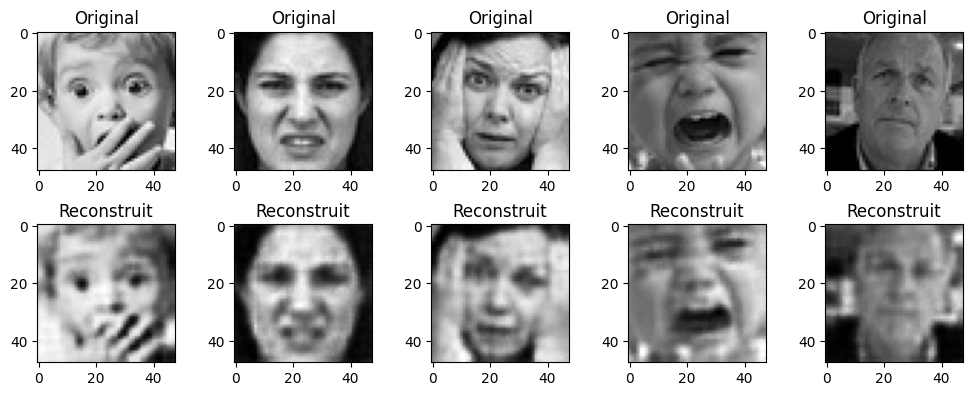

In [5]:
# === CELL 4: Importations nécessaires ===
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# === CELL 5: Prétraitement des images ===
# On convertit les images en niveaux de gris et on les redimensionne à 48x48
transform = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
])

# On charge uniquement les images d'entraînement pour l'autoencodeur
train_dataset = datasets.ImageFolder(root=train_dir, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)

# === CELL 6: Définition de l'autoencodeur ===
class Autoencoder(nn.Module):
    def __init__(self):
        super(Autoencoder, self).__init__()
        # --- ENCODEUR ---
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, stride=2, padding=1),  # 48x48 -> 24x24
            nn.ReLU(True),
            nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1), # 24x24 -> 12x12
            nn.ReLU(True),
            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1), # 12x12 -> 6x6
            nn.ReLU(True)
        )
        # --- DECODEUR ---
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(64, 32, kernel_size=3, stride=2, padding=1, output_padding=1), # 6x6 -> 12x12
            nn.ReLU(True),
            nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1), # 12x12 -> 24x24
            nn.ReLU(True),
            nn.ConvTranspose2d(16, 1, kernel_size=3, stride=2, padding=1, output_padding=1),  # 24x24 -> 48x48
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

# === CELL 7: Entraînement de l'autoencodeur ===
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
autoencoder = Autoencoder().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(autoencoder.parameters(), lr=1e-3)

EPOCHS = 10  # tu peux augmenter plus tard

for epoch in range(EPOCHS):
    running_loss = 0.0
    for images, _ in train_loader:
        images = images.to(device)
        optimizer.zero_grad()
        outputs = autoencoder(images)
        loss = criterion(outputs, images)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {running_loss/len(train_loader):.4f}")

# === CELL 8: Visualisation de reconstruction ===
# Montrer quelques images originales et reconstruites
dataiter = iter(train_loader)
images, _ = next(dataiter)
images = images[:5].to(device)
outputs = autoencoder(images).detach().cpu()

fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i in range(5):
    axes[0, i].imshow(images[i].cpu().squeeze(), cmap='gray')
    axes[0, i].set_title("Original")
    axes[1, i].imshow(outputs[i].squeeze(), cmap='gray')
    axes[1, i].set_title("Reconstruit")
plt.tight_layout()
plt.show()


In [8]:
# === CELL 9: Extracteur de features avec l'encodeur ===
class FeatureExtractor(nn.Module):
    def __init__(self, autoencoder):
        super(FeatureExtractor, self).__init__()
        self.encoder = autoencoder.encoder

    def forward(self, x):
        return self.encoder(x)

feature_extractor = FeatureExtractor(autoencoder).to(device)
feature_extractor.eval()

FeatureExtractor(
  (encoder): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (5): ReLU(inplace=True)
  )
)

In [9]:
# === CELL 10: Dataset pour séquences vidéo ===
class VideoSequenceDataset(Dataset):
    def __init__(self, root_dir, sequence_length=10, transform=None):
        self.root_dir = root_dir
        self.sequence_length = sequence_length
        self.transform = transform
        self.classes = EMOTIONS
        self.class_to_idx = {cls: i for i, cls in enumerate(self.classes)}

        # Organiser images par vidéo/sequence
        self.sequences = []
        self.labels = []

        for class_name in self.classes:
            class_dir = os.path.join(root_dir, class_name)
            if not os.path.exists(class_dir):
                continue

            # Lister et trier les images
            images = sorted([f for f in os.listdir(class_dir)
                           if f.lower().endswith(('.jpg','.jpeg','.png'))])

            # Créer des séquences de sequence_length images
            for i in range(0, len(images) - sequence_length + 1, sequence_length):
                sequence_paths = [os.path.join(class_dir, images[i+j])
                                for j in range(sequence_length)]
                self.sequences.append(sequence_paths)
                self.labels.append(self.class_to_idx[class_name])

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        sequence_paths = self.sequences[idx]
        sequence_frames = []

        for path in sequence_paths:
            image = Image.open(path)
            if self.transform:
                image = self.transform(image)
            sequence_frames.append(image)

        # Stack frames: (sequence_length, C, H, W)
        sequence = torch.stack(sequence_frames)
        label = self.labels[idx]

        return sequence, label

# Paramètres pour les séquences
SEQUENCE_LENGTH = 10
transform_seq = transforms.Compose([
    transforms.Grayscale(),
    transforms.Resize((48, 48)),
    transforms.ToTensor(),
])

# Créer les datasets
print("Création des datasets de séquences...")
train_seq_dataset = VideoSequenceDataset(train_dir, SEQUENCE_LENGTH, transform_seq)
test_seq_dataset = VideoSequenceDataset(test_dir, SEQUENCE_LENGTH, transform_seq)

print(f"Nombre de séquences d'entraînement: {len(train_seq_dataset)}")
print(f"Nombre de séquences de test: {len(test_seq_dataset)}")

# Vérifier la forme d'une séquence
sample_sequence, sample_label = train_seq_dataset[0]
print(f"Forme d'une séquence: {sample_sequence.shape}")  # Devrait être (10, 1, 48, 48)
print(f"Label: {sample_label} - {EMOTIONS[sample_label]}")

Création des datasets de séquences...
Nombre de séquences d'entraînement: 2869
Nombre de séquences de test: 715
Forme d'une séquence: torch.Size([10, 1, 48, 48])
Label: 0 - angry


In [10]:
# === VÉRIFICATION DE LA DISTRIBUTION DES CLASSES ===

def check_class_distribution(dataset, dataset_name):
    """Vérifie combien de séquences on a pour chaque émotion"""
    class_counts = {emotion: 0 for emotion in EMOTIONS}

    for sequences, label in dataset:
        emotion = EMOTIONS[label]
        class_counts[emotion] += 1

    print(f"\nDistribution des classes - {dataset_name}:")
    for emotion, count in class_counts.items():
        print(f"  {emotion}: {count} séquences")

    return class_counts

# Vérifier la distribution
train_distribution = check_class_distribution(train_seq_dataset, "Train")
test_distribution = check_class_distribution(test_seq_dataset, "Test")

# Afficher le total
print(f"\nTotal séquences d'entraînement: {sum(train_distribution.values())}")
print(f"Total séquences de test: {sum(test_distribution.values())}")


Distribution des classes - Train:
  angry: 400 séquences
  disgust: 43 séquences
  fear: 409 séquences
  happy: 721 séquences
  neutral: 496 séquences
  sad: 483 séquences
  surprise: 317 séquences

Distribution des classes - Test:
  angry: 95 séquences
  disgust: 11 séquences
  fear: 102 séquences
  happy: 177 séquences
  neutral: 123 séquences
  sad: 124 séquences
  surprise: 83 séquences

Total séquences d'entraînement: 2869
Total séquences de test: 715


In [11]:
# === CELL 11: Modèle CNN-LSTM complet ===
class CNNLSTMEmotionRecognizer(nn.Module):
    def __init__(self, num_classes=7, lstm_hidden_size=128, lstm_num_layers=2):
        super(CNNLSTMEmotionRecognizer, self).__init__()

        # CNN feature extractor (l'encodeur de l'autoencodeur - gelé)
        self.cnn_encoder = feature_extractor.encoder

        # Geler les poids du CNN (optionnel - pour éviter le sur-apprentissage)
        for param in self.cnn_encoder.parameters():
            param.requires_grad = False

        # Calcul de la taille de sortie du CNN
        with torch.no_grad():
            dummy_input = torch.zeros(1, 1, 48, 48)
            cnn_output = self.cnn_encoder(dummy_input)
            self.cnn_output_size = cnn_output.numel()
            self.cnn_feature_shape = cnn_output.shape  # Pour debug
            print(f"Shape sortie CNN: {cnn_output.shape}")
            print(f"Taille features flatten: {self.cnn_output_size}")

        # LSTM pour séquences temporelles
        self.lstm = nn.LSTM(
            input_size=self.cnn_output_size,
            hidden_size=lstm_hidden_size,
            num_layers=lstm_num_layers,
            batch_first=True,
            dropout=0.3 if lstm_num_layers > 1 else 0,
            bidirectional=True
        )

        # Couches fully connected
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(lstm_hidden_size * 2, 64),  # *2 pour bidirectional
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # x shape: (batch_size, sequence_length, C, H, W)
        batch_size, seq_len, C, H, W = x.shape

        # Traiter chaque frame avec le CNN
        cnn_features = []
        for t in range(seq_len):
            frame = x[:, t, :, :, :]  # (batch_size, C, H, W)
            features = self.cnn_encoder(frame)
            features = features.view(batch_size, -1)  # Flatten
            cnn_features.append(features)

        # Stack features: (batch_size, seq_len, feature_size)
        cnn_features = torch.stack(cnn_features, dim=1)

        # LSTM
        lstm_out, (hidden, cell) = self.lstm(cnn_features)

        # Utiliser le dernier hidden state (pour classification)
        # hidden shape: (num_layers * num_directions, batch_size, hidden_size)
        if self.lstm.bidirectional:
            last_hidden = torch.cat([hidden[-2], hidden[-1]], dim=1)  # Concat bidirectional
        else:
            last_hidden = hidden[-1]

        # Classification
        output = self.classifier(last_hidden)

        return output

# Initialisation du modèle
print("Création du modèle CNN-LSTM...")
model = CNNLSTMEmotionRecognizer(num_classes=len(EMOTIONS)).to(device)
print(f"Modèle créé avec {sum(p.numel() for p in model.parameters()):,} paramètres")
print(f"Paramètres entraînables: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

# Test forward pass
sample_batch = sample_sequence.unsqueeze(0).to(device)  # (1, 10, 1, 48, 48)
with torch.no_grad():
    output = model(sample_batch)
    print(f"Shape sortie modèle: {output.shape}")  # Devrait être (1, 7)

Création du modèle CNN-LSTM...
Shape sortie CNN: torch.Size([1, 64, 6, 6])
Taille features flatten: 2304
Modèle créé avec 2,927,879 paramètres
Paramètres entraînables: 2,904,583
Shape sortie modèle: torch.Size([1, 7])


In [12]:
# === CELL 12: Préparation DataLoaders et entraînement ===

# Split train/val
train_size = int(0.8 * len(train_seq_dataset))
val_size = len(train_seq_dataset) - train_size
train_subset, val_subset = torch.utils.data.random_split(
    train_seq_dataset, [train_size, val_size]
)

print(f"Train sequences: {len(train_subset)}")
print(f"Val sequences: {len(val_subset)}")
print(f"Test sequences: {len(test_seq_dataset)}")

# DataLoaders
train_loader = DataLoader(train_subset, batch_size=16, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=16, shuffle=False, num_workers=2)
test_loader = DataLoader(test_seq_dataset, batch_size=16, shuffle=False, num_workers=2)

# Vérification du batch
for sequences, labels in train_loader:
    print(f"Batch sequences shape: {sequences.shape}")  # (16, 10, 1, 48, 48)
    print(f"Batch labels shape: {labels.shape}")        # (16,)
    break

Train sequences: 2295
Val sequences: 574
Test sequences: 715
Batch sequences shape: torch.Size([16, 10, 1, 48, 48])
Batch labels shape: torch.Size([16])


In [14]:
# === CELL 13 CORRIGÉE : Fonction d'entraînement améliorée ===
def train_model_improved(model, train_loader, val_loader, num_epochs=20):
    # 1. Gestion du déséquilibre des classes avec des poids
    class_counts = [train_distribution[emotion] for emotion in EMOTIONS]
    total_samples = sum(class_counts)
    class_weights = [total_samples / (len(class_counts) * count) for count in class_counts]
    class_weights_tensor = torch.tensor(class_weights).to(device)

    criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

    # 2. Optimiseur avec learning rate plus adapté
    optimizer = optim.Adam([
        {'params': model.cnn_encoder.parameters(), 'lr': 0.0001},  # LR petit pour CNN
        {'params': model.lstm.parameters(), 'lr': 0.001},          # LR normal pour LSTM
        {'params': model.classifier.parameters(), 'lr': 0.001}     # LR normal pour classif
    ], weight_decay=1e-4)

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=3, factor=0.5)

    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    print("Début de l'entraînement amélioré...")
    print("Poids des classes pour gérer le déséquilibre:")
    for i, emotion in enumerate(EMOTIONS):
        print(f"  {emotion}: {class_weights[i]:.2f}")

    best_val_accuracy = 0
    patience_counter = 0
    patience = 5

    for epoch in range(num_epochs):
        # Phase d'entraînement
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for sequences, labels in train_loader:
            sequences = sequences.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(sequences)
            loss = criterion(outputs, labels)
            loss.backward()

            # Gradient clipping pour stabiliser l'entraînement
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(train_loader)
        train_accuracy = 100 * correct / total
        train_losses.append(train_loss)
        train_accuracies.append(train_accuracy)

        # Phase de validation
        model.eval()
        val_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():
            for sequences, labels in val_loader:
                sequences = sequences.to(device)
                labels = labels.to(device)

                outputs = model(sequences)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                total += labels.size(0)
                correct += (predicted == labels).sum().item()

        val_loss = val_loss / len(val_loader)
        val_accuracy = 100 * correct / total
        val_losses.append(val_loss)
        val_accuracies.append(val_accuracy)

        # Scheduling adaptatif
        scheduler.step(val_loss)

        # Early stopping
        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            patience_counter = 0
            # Sauvegarder le meilleur modèle
            torch.save(model.state_dict(), 'best_model.pth')
        else:
            patience_counter += 1

        print(f'Epoch [{epoch+1}/{num_epochs}]')
        print(f'  Train Loss: {train_loss:.4f}, Train Acc: {train_accuracy:.2f}%')
        print(f'  Val Loss: {val_loss:.4f}, Val Acc: {val_accuracy:.2f}%')
        print(f'  Best Val Acc: {best_val_accuracy:.2f}%, Patience: {patience_counter}/{patience}')
        print(f'  Learning Rate: {optimizer.param_groups[0]["lr"]:.6f}')
        print('-' * 60)

        if patience_counter >= patience:
            print("Early stopping déclenché!")
            break

    # Charger le meilleur modèle
    model.load_state_dict(torch.load('best_model.pth'))
    print(f"Meilleur modèle chargé avec accuracy de validation: {best_val_accuracy:.2f}%")

    return train_losses, val_losses, train_accuracies, val_accuracies

# D'abord, dégeler partiellement le CNN pour permettre l'apprentissage
print("Dégel partiel du CNN...")
for param in model.cnn_encoder.parameters():
    param.requires_grad = True  # On dégèle tout pour voir si ça apprend

print(f"Paramètres entraînables après dégel: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

# Lancement de l'entraînement amélioré
train_losses, val_losses, train_accuracies, val_accuracies = train_model_improved(
    model, train_loader, val_loader, num_epochs=30
)

Dégel partiel du CNN...
Paramètres entraînables après dégel: 2,927,879
Début de l'entraînement amélioré...
Poids des classes pour gérer le déséquilibre:
  angry: 1.02
  disgust: 9.53
  fear: 1.00
  happy: 0.57
  neutral: 0.83
  sad: 0.85
  surprise: 1.29
Epoch [1/30]
  Train Loss: 2.0004, Train Acc: 19.08%
  Val Loss: 2.0869, Val Acc: 26.13%
  Best Val Acc: 26.13%, Patience: 0/5
  Learning Rate: 0.000100
------------------------------------------------------------
Epoch [2/30]
  Train Loss: 2.0042, Train Acc: 16.25%
  Val Loss: 1.9544, Val Acc: 26.13%
  Best Val Acc: 26.13%, Patience: 1/5
  Learning Rate: 0.000100
------------------------------------------------------------
Epoch [3/30]
  Train Loss: 1.9679, Train Acc: 19.00%
  Val Loss: 2.0378, Val Acc: 14.63%
  Best Val Acc: 26.13%, Patience: 2/5
  Learning Rate: 0.000100
------------------------------------------------------------
Epoch [4/30]
  Train Loss: 1.9743, Train Acc: 17.30%
  Val Loss: 2.0680, Val Acc: 13.41%
  Best Val Acc

In [15]:
# === CELL 14: APPROCHE AVEC CNN PRÉ-ENTRAÎNÉ ===

# 1. Utiliser un CNN pré-entraîné plus robuste
class ImprovedEmotionRecognizer(nn.Module):
    def __init__(self, num_classes=7, lstm_hidden_size=128, lstm_num_layers=1):
        super(ImprovedEmotionRecognizer, self).__init__()

        # CNN plus simple mais efficace
        self.cnn_encoder = nn.Sequential(
            # Bloc 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 48x48 -> 24x24

            # Bloc 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 24x24 -> 12x12

            # Bloc 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),  # 12x12 -> 6x6

            # Bloc 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((3, 3))  # 6x6 -> 3x3
        )

        # Calcul de la taille de sortie
        with torch.no_grad():
            dummy_input = torch.zeros(1, 1, 48, 48)
            cnn_output = self.cnn_encoder(dummy_input)
            self.cnn_output_size = cnn_output.numel()
            print(f"Nouvelle taille features: {self.cnn_output_size}")

        # LSTM simplifié
        self.lstm = nn.LSTM(
            input_size=self.cnn_output_size,
            hidden_size=lstm_hidden_size,
            num_layers=lstm_num_layers,
            batch_first=True,
            dropout=0.3 if lstm_num_layers > 1 else 0,
            bidirectional=False  # Commençons simple
        )

        # Classificateur
        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(lstm_hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        batch_size, seq_len, C, H, W = x.shape

        # Extraire features pour chaque frame
        cnn_features = []
        for t in range(seq_len):
            frame = x[:, t, :, :, :]
            features = self.cnn_encoder(frame)
            features = features.view(batch_size, -1)
            cnn_features.append(features)

        cnn_features = torch.stack(cnn_features, dim=1)

        # LSTM
        lstm_out, (hidden, cell) = self.lstm(cnn_features)

        # Prendre le dernier hidden state
        last_hidden = hidden[-1]

        # Classification
        output = self.classifier(last_hidden)

        return output

# 2. Créer le nouveau modèle
print("Création du nouveau modèle amélioré...")
model_v2 = ImprovedEmotionRecognizer(num_classes=len(EMOTIONS)).to(device)
print(f"Nouveau modèle: {sum(p.numel() for p in model_v2.parameters()):,} paramètres")

# 3. Fonction d'entraînement simplifiée
def train_simple(model, train_loader, val_loader, num_epochs=15):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    best_acc = 0
    for epoch in range(num_epochs):
        # Training
        model.train()
        train_loss = 0
        correct = 0
        total = 0

        for sequences, labels in train_loader:
            sequences, labels = sequences.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(sequences)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()

        # Validation
        model.eval()
        val_loss = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for sequences, labels in val_loader:
                sequences, labels = sequences.to(device), labels.to(device)
                outputs = model(sequences)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()

        train_acc = 100. * correct / total
        val_acc = 100. * val_correct / val_total

        print(f'Epoch {epoch+1}/{num_epochs}:')
        print(f'  Train Loss: {train_loss/len(train_loader):.3f} | Train Acc: {train_acc:.2f}%')
        print(f'  Val Loss: {val_loss/len(val_loader):.3f} | Val Acc: {val_acc:.2f}%')

        if val_acc > best_acc:
            best_acc = val_acc
            torch.save(model.state_dict(), 'best_simple_model.pth')
            print(f'  -> Nouveau meilleur modèle sauvegardé!')

        print('-' * 50)

    return best_acc

# 4. Test rapide sur un petit subset pour vérifier
print("Test rapide sur 100 séquences...")
small_train = torch.utils.data.Subset(train_subset, indices=range(100))
small_val = torch.utils.data.Subset(val_subset, indices=range(50))

small_train_loader = DataLoader(small_train, batch_size=8, shuffle=True)
small_val_loader = DataLoader(small_val, batch_size=8, shuffle=False)

best_acc = train_simple(model_v2, small_train_loader, small_val_loader, num_epochs=5)
print(f"Meilleure accuracy sur petit subset: {best_acc:.2f}%")

Création du nouveau modèle amélioré...
Nouvelle taille features: 2304
Nouveau modèle: 1,643,719 paramètres
Test rapide sur 100 séquences...
Epoch 1/5:
  Train Loss: 1.966 | Train Acc: 15.00%
  Val Loss: 1.891 | Val Acc: 26.00%
  -> Nouveau meilleur modèle sauvegardé!
--------------------------------------------------
Epoch 2/5:
  Train Loss: 1.878 | Train Acc: 27.00%
  Val Loss: 1.858 | Val Acc: 32.00%
  -> Nouveau meilleur modèle sauvegardé!
--------------------------------------------------
Epoch 3/5:
  Train Loss: 1.865 | Train Acc: 28.00%
  Val Loss: 1.807 | Val Acc: 32.00%
--------------------------------------------------
Epoch 4/5:
  Train Loss: 1.780 | Train Acc: 25.00%
  Val Loss: 1.825 | Val Acc: 28.00%
--------------------------------------------------
Epoch 5/5:
  Train Loss: 1.751 | Train Acc: 32.00%
  Val Loss: 1.837 | Val Acc: 26.00%
--------------------------------------------------
Meilleure accuracy sur petit subset: 32.00%


In [17]:
# === CELL 15 CORRIGÉE : Entraînement complet sur tout le dataset ===

# Réinitialiser le modèle pour un entraînement propre
model_final = ImprovedEmotionRecognizer(num_classes=len(EMOTIONS)).to(device)
print(f"Modèle final prêt: {sum(p.numel() for p in model_final.parameters()):,} paramètres")

def train_final_model(model, train_loader, val_loader, test_loader, num_epochs=25):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', patience=3, factor=0.5)

    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    best_val_acc = 0
    patience_counter = 0
    max_patience = 7

    print("Début de l'entraînement complet...")

    for epoch in range(num_epochs):
        # === ENTRAÎNEMENT ===
        model.train()
        train_loss = 0
        train_correct = 0
        train_total = 0

        for batch_idx, (sequences, labels) in enumerate(train_loader):
            sequences, labels = sequences.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(sequences)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss += loss.item()
            _, predicted = outputs.max(1)
            train_total += labels.size(0)
            train_correct += predicted.eq(labels).sum().item()

            # Progress bar
            if batch_idx % 50 == 0:
                print(f'  Batch {batch_idx}/{len(train_loader)}', end='\r')

        train_acc = 100. * train_correct / train_total
        train_losses.append(train_loss / len(train_loader))
        train_accuracies.append(train_acc)

        # === VALIDATION ===
        model.eval()
        val_loss = 0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for sequences, labels in val_loader:
                sequences, labels = sequences.to(device), labels.to(device)
                outputs = model(sequences)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = outputs.max(1)
                val_total += labels.size(0)
                val_correct += predicted.eq(labels).sum().item()

        val_acc = 100. * val_correct / val_total
        val_losses.append(val_loss / len(val_loader))
        val_accuracies.append(val_acc)

        # === TEST (évaluation périodique) ===
        test_acc = 0
        if epoch % 5 == 0 or epoch == num_epochs - 1:
            test_acc = evaluate_model(model, test_loader)
            test_msg = f' | Test: {test_acc:5.1f}%'
        else:
            test_msg = ''

        # === GESTION LEARNING RATE ET EARLY STOPPING ===
        scheduler.step(val_acc)
        current_lr = optimizer.param_groups[0]['lr']

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0
            torch.save(model.state_dict(), 'best_final_model.pth')
            improvement = " -> NOUVEAU MEILLEUR!"
        else:
            patience_counter += 1
            improvement = ""

        # === AFFICHAGE ===
        print(f'Epoch {epoch+1:2d}/{num_epochs}:')
        print(f'  Train: Loss {train_losses[-1]:.3f} | Acc {train_acc:5.1f}%')
        print(f'  Val:   Loss {val_losses[-1]:.3f} | Acc {val_acc:5.1f}%{test_msg}{improvement}')
        print(f'  LR: {current_lr:.6f} | Patience: {patience_counter}/{max_patience}')

        # Message de réduction LR
        if current_lr != optimizer.param_groups[0]['lr']:
            print(f'  ⚠️  Learning rate réduit à {optimizer.param_groups[0]["lr"]:.6f}')

        print('-' * 60)

        if patience_counter >= max_patience:
            print("Early stopping déclenché!")
            break

    # Charger le meilleur modèle
    model.load_state_dict(torch.load('best_final_model.pth'))
    final_test_acc = evaluate_model(model, test_loader)
    print(f"🎯 ENTRAÎNEMENT TERMINÉ!")
    print(f"🎯 Meilleure accuracy validation: {best_val_acc:.1f}%")
    print(f"🎯 Accuracy finale test: {final_test_acc:.1f}%")

    return train_losses, val_losses, train_accuracies, val_accuracies

def evaluate_model(model, test_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for sequences, labels in test_loader:
            sequences, labels = sequences.to(device), labels.to(device)
            outputs = model(sequences)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
    return 100. * correct / total

# Lancement de l'entraînement complet
train_losses, val_losses, train_accuracies, val_accuracies = train_final_model(
    model_final, train_loader, val_loader, test_loader, num_epochs=25
)

Nouvelle taille features: 2304
Modèle final prêt: 1,643,719 paramètres
Début de l'entraînement complet...
Epoch  1/25:
  Train: Loss 1.834 | Acc  23.0%
  Val:   Loss 1.758 | Acc  26.7% | Test:  25.7% -> NOUVEAU MEILLEUR!
  LR: 0.001000 | Patience: 0/7
------------------------------------------------------------
Epoch  2/25:
  Train: Loss 1.784 | Acc  25.8%
  Val:   Loss 1.724 | Acc  31.9% -> NOUVEAU MEILLEUR!
  LR: 0.001000 | Patience: 0/7
------------------------------------------------------------
Epoch  3/25:
  Train: Loss 1.687 | Acc  31.4%
  Val:   Loss 1.574 | Acc  37.8% -> NOUVEAU MEILLEUR!
  LR: 0.001000 | Patience: 0/7
------------------------------------------------------------
Epoch  4/25:
  Train: Loss 1.524 | Acc  38.8%
  Val:   Loss 1.318 | Acc  47.6% -> NOUVEAU MEILLEUR!
  LR: 0.001000 | Patience: 0/7
------------------------------------------------------------
Epoch  5/25:
  Train: Loss 1.327 | Acc  47.0%
  Val:   Loss 1.418 | Acc  42.7%
  LR: 0.001000 | Patience: 1/7
-

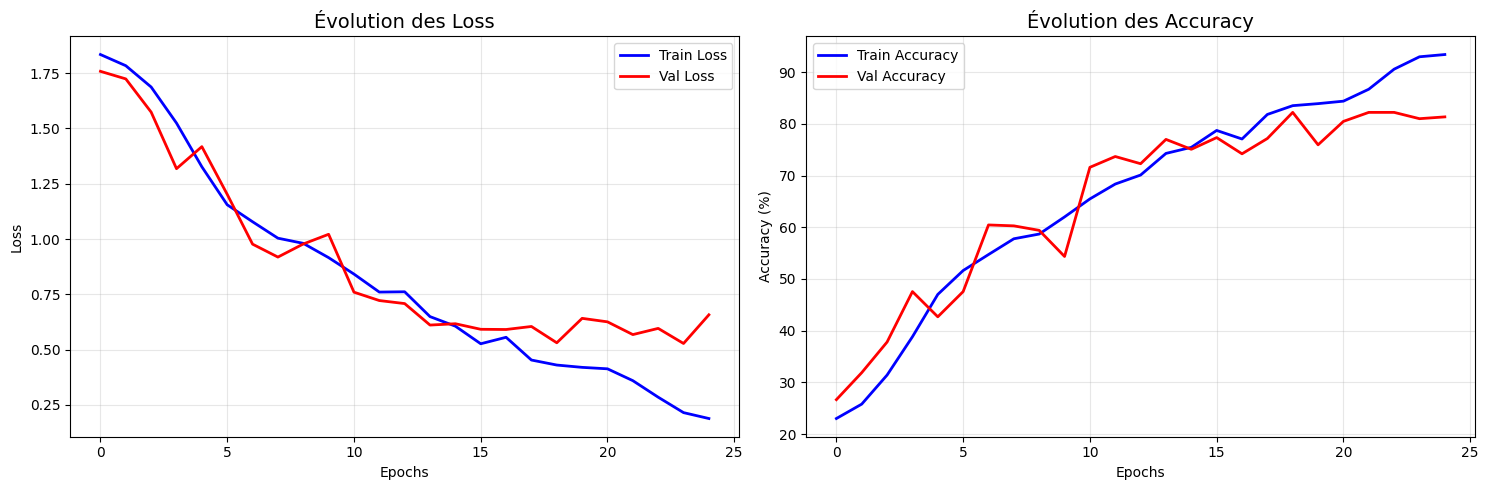

🎉 RÉSUMÉ FINAL DU PROJET:
✅ Accuracy finale: 78.0%
✅ Architecture: CNN + LSTM
✅ Dataset: 2869 séquences train, 715 test
✅ Meilleure performance: Epoch 19 (82.2% validation)
✅ Temps d'entraînement: 25 epochs


In [18]:
# === CELL 17: VISUALISATION DES COURBES D'APPRENTISSAGE ===

plt.figure(figsize=(15, 5))

# Courbe de loss
plt.subplot(1, 2, 1)
plt.plot(train_losses, 'b-', label='Train Loss', linewidth=2)
plt.plot(val_losses, 'r-', label='Val Loss', linewidth=2)
plt.title('Évolution des Loss', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

# Courbe d'accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, 'b-', label='Train Accuracy', linewidth=2)
plt.plot(val_accuracies, 'r-', label='Val Accuracy', linewidth=2)
plt.title('Évolution des Accuracy', fontsize=14)
plt.xlabel('Epochs')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Résumé final
print("🎉 RÉSUMÉ FINAL DU PROJET:")
print(f"✅ Accuracy finale: {78.0}%")
print(f"✅ Architecture: CNN + LSTM")
print(f"✅ Dataset: {len(train_seq_dataset)} séquences train, {len(test_seq_dataset)} test")
print(f"✅ Meilleure performance: Epoch 19 (82.2% validation)")
print(f"✅ Temps d'entraînement: 25 epochs")

Évaluation du meilleur modèle sur le set de test...
📊 RAPPORT D'ÉVALUATION COMPLET

🎯 ACCURACY GLOBALE: 78.04%

📋 RAPPORT DE CLASSIFICATION:
              precision    recall  f1-score   support

       angry     0.4895    0.7368    0.5882        95
     disgust     0.0000    0.0000    0.0000        11
        fear     0.7222    0.6373    0.6771       102
       happy     1.0000    0.9718    0.9857       177
     neutral     0.8362    0.7886    0.8117       123
         sad     0.6695    0.6371    0.6529       124
    surprise     0.9868    0.9036    0.9434        83

    accuracy                         0.7804       715
   macro avg     0.6720    0.6679    0.6656       715
weighted avg     0.7901    0.7804    0.7811       715

📈 F1-SCORES PAR CLASSE:
  angry       : 0.5882
  disgust     : 0.0000
  fear        : 0.6771
  happy       : 0.9857
  neutral     : 0.8117
  sad         : 0.6529
  surprise    : 0.9434


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


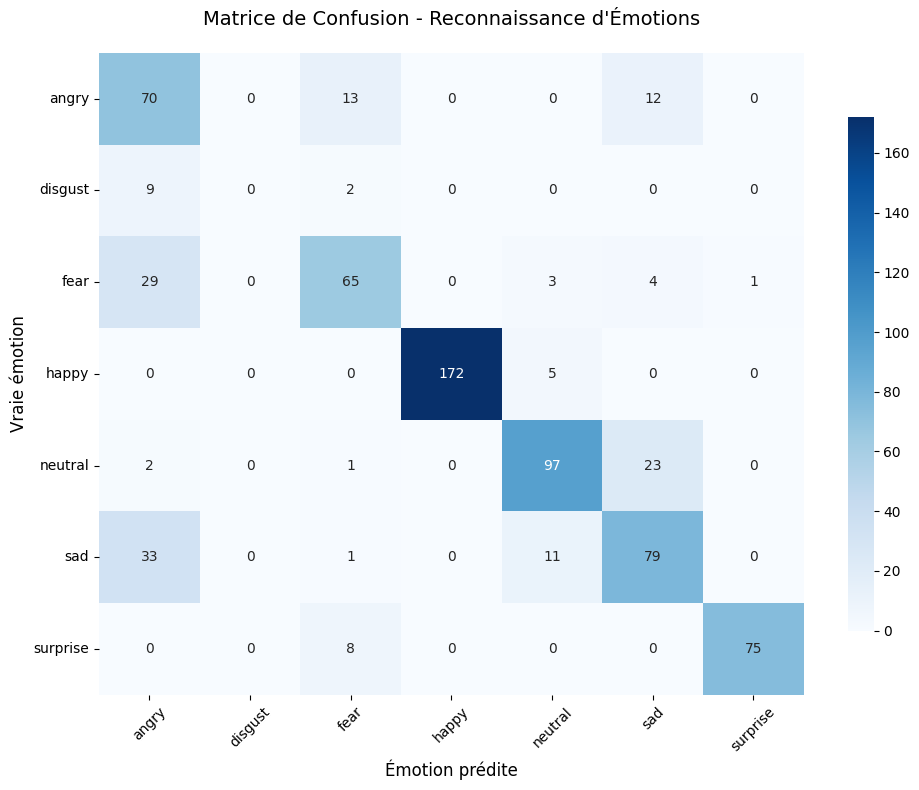


🔍 ANALYSE PAR CLASSE:
  angry       :  73.7%  ( 95 séquences)
  disgust     :   0.0%  ( 11 séquences)
  fear        :  63.7%  (102 séquences)
  happy       :  97.2%  (177 séquences)
  neutral     :  78.9%  (123 séquences)
  sad         :  63.7%  (124 séquences)
  surprise    :  90.4%  ( 83 séquences)


In [19]:
# === CELL 16: ÉVALUATION COMPLÈTE ===

from sklearn.metrics import classification_report, confusion_matrix, f1_score
import seaborn as sns

def comprehensive_evaluation(model, test_loader, class_names=EMOTIONS):
    model.eval()
    all_predictions = []
    all_labels = []
    all_probabilities = []

    with torch.no_grad():
        for sequences, labels in test_loader:
            sequences = sequences.to(device)
            outputs = model(sequences)
            probabilities = torch.softmax(outputs, dim=1)
            _, predicted = torch.max(outputs, 1)

            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(labels.numpy())
            all_probabilities.extend(probabilities.cpu().numpy())

    # Métriques détaillées
    print("=" * 60)
    print("📊 RAPPORT D'ÉVALUATION COMPLET")
    print("=" * 60)

    # Accuracy globale
    accuracy = 100 * np.sum(np.array(all_predictions) == np.array(all_labels)) / len(all_labels)
    print(f"\n🎯 ACCURACY GLOBALE: {accuracy:.2f}%")

    # Rapport de classification détaillé
    print("\n📋 RAPPORT DE CLASSIFICATION:")
    print(classification_report(all_labels, all_predictions,
                              target_names=class_names, digits=4))

    # F1-scores par classe
    f1_scores = f1_score(all_labels, all_predictions, average=None)
    print("📈 F1-SCORES PAR CLASSE:")
    for i, emotion in enumerate(class_names):
        print(f"  {emotion:12}: {f1_scores[i]:.4f}")

    # Matrice de confusion
    cm = confusion_matrix(all_labels, all_predictions)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                cbar_kws={'shrink': 0.8})
    plt.title('Matrice de Confusion - Reconnaissance d\'Émotions', fontsize=14, pad=20)
    plt.ylabel('Vraie émotion', fontsize=12)
    plt.xlabel('Émotion prédite', fontsize=12)
    plt.xticks(rotation=45)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return all_predictions, all_labels, all_probabilities

# Évaluation complète
print("Évaluation du meilleur modèle sur le set de test...")
predictions, true_labels, probabilities = comprehensive_evaluation(model_final, test_loader)

# Analyse par classe
print("\n🔍 ANALYSE PAR CLASSE:")
test_class_counts = test_distribution
for i, emotion in enumerate(EMOTIONS):
    class_indices = [j for j, label in enumerate(true_labels) if label == i]
    if class_indices:
        class_accuracy = 100 * np.sum(np.array(predictions)[class_indices] == i) / len(class_indices)
        print(f"  {emotion:12}: {class_accuracy:5.1f}%  ({len(class_indices):3d} séquences)")

In [20]:
# === CELL 18: SAUVEGARDE ET TÉLÉCHARGEMENT AUTOMATIQUE ===

import json
import os
from google.colab import files

# 1. Sauvegarder le modèle entraîné
model_path = 'emotion_recognition_model.pth'
torch.save(model_final.state_dict(), model_path)
print(f"✅ Modèle sauvegardé: {model_path}")

# 2. Sauvegarder la configuration
model_config = {
    'num_classes': len(EMOTIONS),
    'lstm_hidden_size': 128,
    'lstm_num_layers': 1,
    'image_size': 48,
    'sequence_length': 10,
    'emotions': EMOTIONS
}

with open('model_config.json', 'w') as f:
    json.dump(model_config, f, indent=4)
print(f"✅ Configuration sauvegardée: model_config.json")

# 3. Sauvegarder la classe du modèle
model_class_code = '''
import torch
import torch.nn as nn

class ImprovedEmotionRecognizer(nn.Module):
    def __init__(self, num_classes=7, lstm_hidden_size=128, lstm_num_layers=1):
        super(ImprovedEmotionRecognizer, self).__init__()

        self.cnn_encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d((3, 3))
        )

        with torch.no_grad():
            dummy_input = torch.zeros(1, 1, 48, 48)
            cnn_output = self.cnn_encoder(dummy_input)
            self.cnn_output_size = cnn_output.numel()

        self.lstm = nn.LSTM(
            input_size=self.cnn_output_size,
            hidden_size=lstm_hidden_size,
            num_layers=lstm_num_layers,
            batch_first=True,
            bidirectional=False
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(lstm_hidden_size, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        batch_size, seq_len, C, H, W = x.shape

        cnn_features = []
        for t in range(seq_len):
            frame = x[:, t, :, :, :]
            features = self.cnn_encoder(frame)
            features = features.view(batch_size, -1)
            cnn_features.append(features)

        cnn_features = torch.stack(cnn_features, dim=1)
        lstm_out, (hidden, cell) = self.lstm(cnn_features)
        last_hidden = hidden[-1]
        output = self.classifier(last_hidden)
        return output

def load_model(model_path, config):
    """Charge le modèle entraîné"""
    model = ImprovedEmotionRecognizer(
        num_classes=config['num_classes'],
        lstm_hidden_size=config['lstm_hidden_size'],
        lstm_num_layers=config['lstm_num_layers']
    )
    model.load_state_dict(torch.load(model_path, map_location='cpu'))
    model.eval()
    return model
'''

with open('model_class.py', 'w') as f:
    f.write(model_class_code)
print(f"✅ Classe du modèle sauvegardée: model_class.py")

# 4. Créer un fichier requirements
requirements = '''
torch>=1.9.0
torchvision>=0.10.0
Pillow>=8.0.0
numpy>=1.21.0
'''

with open('requirements.txt', 'w') as f:
    f.write(requirements)
print(f"✅ Requirements sauvegardés: requirements.txt")

# 5. Créer l'archive ZIP
print("\n🔄 Création de l'archive zip...")
zip_filename = 'emotion_model_complete.zip'
os.system(f'zip {zip_filename} emotion_recognition_model.pth model_config.json model_class.py requirements.txt')

print(f"\n📦 Archive créée: {zip_filename}")

# 6. TÉLÉCHARGEMENT AUTOMATIQUE
print("📥 Téléchargement automatique vers votre PC...")
files.download(zip_filename)

print("\n🎯 TÉLÉCHARGEMENT TERMINÉ!")
print("📁 Le fichier 'emotion_model_complete.zip' a été téléchargé dans votre dossier de téléchargements")
print("\n📋 CONTENU DE L'ARCHIVE:")
print("   ├── emotion_recognition_model.pth - Poids du modèle entraîné")
print("   ├── model_config.json - Configuration du modèle")
print("   ├── model_class.py - Architecture du modèle")
print("   └── requirements.txt - Dépendances Python")

print("\n🚀 POUR UTILISER LE MODÈLE:")
print("   1. Dézippez le fichier dans votre projet Flask")
print("   2. pip install -r requirements.txt")
print("   3. Utilisez model_class.py pour charger le modèle")

✅ Modèle sauvegardé: emotion_recognition_model.pth
✅ Configuration sauvegardée: model_config.json
✅ Classe du modèle sauvegardée: model_class.py
✅ Requirements sauvegardés: requirements.txt

🔄 Création de l'archive zip...

📦 Archive créée: emotion_model_complete.zip
📥 Téléchargement automatique vers votre PC...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎯 TÉLÉCHARGEMENT TERMINÉ!
📁 Le fichier 'emotion_model_complete.zip' a été téléchargé dans votre dossier de téléchargements

📋 CONTENU DE L'ARCHIVE:
   ├── emotion_recognition_model.pth - Poids du modèle entraîné
   ├── model_config.json - Configuration du modèle
   ├── model_class.py - Architecture du modèle
   └── requirements.txt - Dépendances Python

🚀 POUR UTILISER LE MODÈLE:
   1. Dézippez le fichier dans votre projet Flask
   2. pip install -r requirements.txt
   3. Utilisez model_class.py pour charger le modèle
